# Space-filling designs: the Latin hypercube

A factorial puts runs at a few levels of each factor and balances the combinations. That suits a
physical experiment with noise, where clean estimates of effects are the goal. A **computer
experiment** is different. The simulation returns the same answer every time it is given the same
inputs, each run may take hours, there may be ten or twenty inputs, and the goal is a cheap
**surrogate** that predicts the simulation anywhere in the region. For that you want runs spread
through the whole space, with every factor seen at many levels.

The **Latin hypercube** does this with a rule a reader can check by eye: cut every axis into $n$
equal bins and put exactly one run in each bin of each axis. This notebook builds one in two
dimensions, compares it with a factorial of the same size, shows that a valid hypercube can still
be a bad one, and then goes to three dimensions to show that **the number of runs does not grow with
the number of factors**.

**Where this fits.** For a physical experiment, with noise, start with
`planning_an_experiment.ipynb` and `factorial_designs.ipynb` in this folder. This notebook is for the
other case: a simulation that you want to replace with a surrogate.

## Setup: where the package lives

This notebook builds its designs by hand and then checks them against `orteach`, the package in
`src/`. Run from a clone of the repository, `../../src` is right there. On Colab there is no clone
until this cell makes one, and no `gurobipy` until it installs it. Nothing here needs a secret.

In [1]:
import os, subprocess, sys

REPO_URL = "https://github.com/sear-labs/teaching-code"
REF = "v1.0.1"                               # the release this notebook ships in: Colab clones THIS

try:
    import google.colab                      # noqa: F401 - succeeds only on Colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if ON_COLAB:
    if not os.path.isdir("/content/teaching-code"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REF, REPO_URL, "/content/teaching-code"], check=True)
    os.chdir("/content/teaching-code/notebooks/15_design_of_experiments")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "gurobipy>=11,<14"], check=True)

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "src")))
try:
    import orteach                            # noqa: F401
except ImportError:
    raise SystemExit("orteach not found: run this notebook from its own folder inside the repository, "
                     "so that ../../src exists.")
root = os.path.abspath(os.path.join("..", ".."))
print("package:", os.path.relpath(os.path.dirname(orteach.__file__), root))

package: src\orteach


## One run in every row and every column

Sixteen runs, two factors, each scaled to $[0, 1]$. For each factor separately: shuffle the numbers
$0$ to $15$ to decide which bin each run takes, then place the run at a random spot inside its bin.
The **permutation** is what makes it a Latin hypercube. It is the same rule as sixteen rooks on a
chessboard, none attacking another.

Before running it, predict: how many different values will factor 1 take across the sixteen runs?
How many would a four-by-four grid give it?

In [2]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from orteach import doe
from orteach.tolerance import AGREEMENT_RTOL, rel_diff

SEED = 2026
N, D = 16, 2
print("seed:", SEED, f"   {N} runs in {D} dimensions")
rng = np.random.default_rng(SEED)

# Build the design one factor (column) at a time
P = np.empty((N, D))                       # N runs, each a point in the unit square
for j in range(D):
    perm = rng.permutation(N)              # which of the N bins each run takes, for this factor
    jitter = rng.random(N)                 # where inside its bin the run sits
    P[:, j] = (perm + jitter) / N

# Check the rule: each factor should use every one of its N bins exactly once
bins = np.floor(P * N).astype(int)
print("bins used by factor 1:", sorted(bins[:, 0].tolist()))
print("bins used by factor 2:", sorted(bins[:, 1].tolist()))
print("first three runs:", np.round(P[:3], 3).tolist())

seed: 2026    16 runs in 2 dimensions
bins used by factor 1: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
bins used by factor 2: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
first three runs: [[0.745, 0.902], [0.79, 0.869], [0.422, 0.77]]


### The picture

The grid lines are the bin edges. The tick marks under each axis are the runs **projected** onto
that axis: the values each factor actually takes.

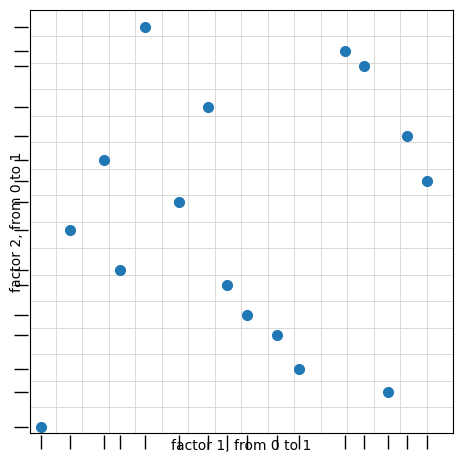

Figure: a 16 by 16 grid holding 16 points. Each of the 16 columns and 16 rows holds exactly one point, and the tick marks along each axis show 16 distinct values of each factor.


In [3]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for k in range(N + 1):                     # the bin edges
    ax.axhline(k / N, color="lightgray", lw=0.6)
    ax.axvline(k / N, color="lightgray", lw=0.6)
ax.plot(P[:, 0], P[:, 1], "o", color="tab:blue", ms=7)
ax.plot(P[:, 0], np.full(N, -0.02), "|", color="black", ms=10, clip_on=False)   # projection onto factor 1
ax.plot(np.full(N, -0.02), P[:, 1], "_", color="black", ms=10, clip_on=False)   # projection onto factor 2
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("factor 1, from 0 to 1")
ax.set_ylabel("factor 2, from 0 to 1")
plt.show()
print(f"Figure: a {N} by {N} grid holding {N} points. Each of the {len(set(bins[:, 0]))} columns and "
      f"{len(set(bins[:, 1]))} rows holds exactly one point, and the tick marks along each axis show "
      f"{len(np.unique(P[:, 0]))} distinct values of each factor.")

## Against a factorial with the same sixteen runs

A four-level factorial in two factors also takes $4 \times 4 = 16$ runs. Put its levels at the
middles of four equal bins and compare two numbers for each design: how many distinct values each
factor takes, and how close the two nearest runs are.

In [4]:
levels = (np.arange(4) + 0.5) / 4                    # the middles of four equal bins
F = np.array(list(itertools.product(levels, repeat=2)))   # every combination: a 4 x 4 factorial
print("factorial: 4 x 4 =", len(F), "runs")
for name, Q in (("factorial", F), ("Latin hypercube", P)):
    # Distance between every pair of runs; keep the smallest (each pair counted once)
    diff = Q[:, None, :] - Q[None, :, :]
    dmin = np.sqrt((diff ** 2).sum(axis=2))[np.triu_indices(len(Q), 1)].min()
    print(f"{name:16} distinct values of factor 1: {len(np.unique(Q[:, 0])):2d}   "
          f"of factor 2: {len(np.unique(Q[:, 1])):2d}   closest pair {dmin:.3f}")

factorial: 4 x 4 = 16 runs
factorial        distinct values of factor 1:  4   of factor 2:  4   closest pair 0.250
Latin hypercube  distinct values of factor 1: 16   of factor 2: 16   closest pair 0.056


Side by side, with each design's projections under the axes:

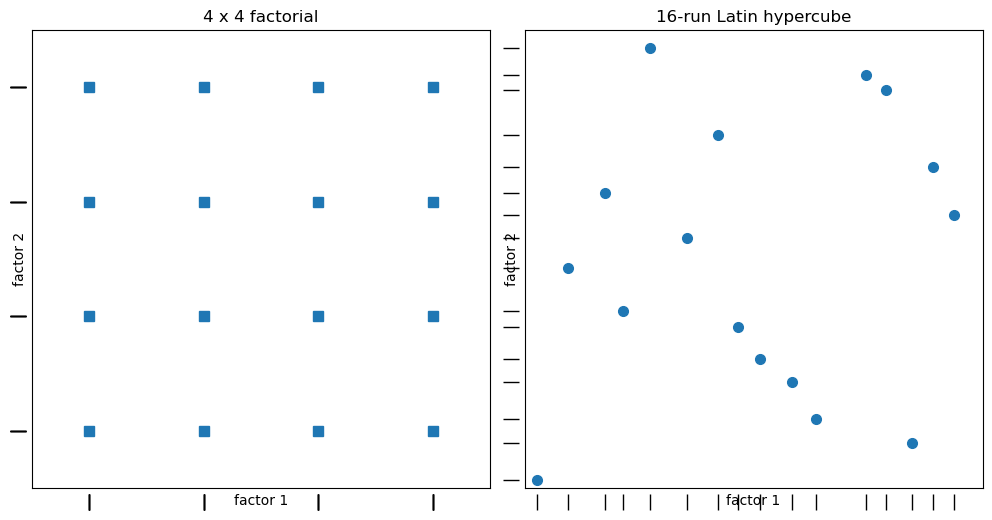

Figure: two designs of 16 runs. Left, a 4 by 4 grid of squares: the tick marks along each axis fall on only 4 values, with four runs stacked on each. Right, the Latin hypercube's circles: 16 distinct tick marks along each axis, one per run.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, Q, marker) in zip(axes, (("4 x 4 factorial", F, "s"), ("16-run Latin hypercube", P, "o"))):
    ax.plot(Q[:, 0], Q[:, 1], marker, color="tab:blue", ms=7)
    ax.plot(Q[:, 0], np.full(len(Q), -0.03), "|", color="black", ms=12, clip_on=False)   # projections
    ax.plot(np.full(len(Q), -0.03), Q[:, 1], "_", color="black", ms=12, clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("factor 1")
    ax.set_ylabel("factor 2")
plt.tight_layout()
plt.show()
print(f"Figure: two designs of {N} runs. Left, a 4 by 4 grid of squares: the tick marks along each axis "
      f"fall on only {len(np.unique(F[:, 0]))} values, with four runs stacked on each. Right, the Latin "
      f"hypercube's circles: {len(np.unique(P[:, 0]))} distinct tick marks along each axis, one per run.")

Suppose only factor 1 matters, and the response is a curve in it. Which design shows you the curve,
and how many points on it does each one give you? Now suppose the question is what happens when
both factors are high at once. Which design would you rather have?

## A valid hypercube can still be a bad design

Sixteen runs along the diagonal satisfy the rule perfectly: one per row, one per column. They also
leave two corners of the square empty, and factor 1 and factor 2 move in lockstep, so their effects
could never be separated. The rule guarantees the projections and nothing about the spread.

The usual repair is **maximin**: among many random hypercubes, keep the one whose closest pair of
runs is farthest apart. The loop below draws 500 and keeps the best. It is a plain search, not an
optimizer, and it is how most software starts.

In [6]:
# The diagonal: run k in bin k on both axes. It obeys the rule too.
diag = np.column_stack([(np.arange(N) + 0.5) / N, (np.arange(N) + 0.5) / N])
pair = np.triu_indices(N, 1)                # every pair of runs, counted once

diff = diag[:, None, :] - diag[None, :, :]
d_diag = np.sqrt((diff ** 2).sum(axis=2))[pair].min()       # closest pair in the diagonal
diff = P[:, None, :] - P[None, :, :]
d_random = np.sqrt((diff ** 2).sum(axis=2))[pair].min()     # closest pair in the random hypercube

# Maximin by plain search: draw TRIES random hypercubes, keep the one whose closest pair is farthest apart
MM_SEED, TRIES = 7, 500
print("maximin seed:", MM_SEED, "   tries:", TRIES)
rng_mm = np.random.default_rng(MM_SEED)
best, best_d = None, -1.0
for t in range(TRIES):
    Q = np.empty((N, D))
    for j in range(D):
        Q[:, j] = (rng_mm.permutation(N) + rng_mm.random(N)) / N
    diff = Q[:, None, :] - Q[None, :, :]
    d_min = np.sqrt((diff ** 2).sum(axis=2))[pair].min()
    if d_min > best_d:
        best, best_d = Q, d_min

# Correlation between the two factors in each design: 0 means their effects can be told apart
r_diag, r_random, r_best = (np.corrcoef(Q[:, 0], Q[:, 1])[0, 1] for Q in (diag, P, best))
print(f"closest pair:            diagonal {d_diag:.3f}   the random hypercube above {d_random:.3f}   "
      f"best of {TRIES} {best_d:.3f}")
print(f"correlation of factors:  diagonal {r_diag:+.3f}   the random hypercube above {r_random:+.3f}   "
      f"best of {TRIES} {r_best:+.3f}")

maximin seed: 7    tries: 500
closest pair:            diagonal 0.088   the random hypercube above 0.056   best of 500 0.157
correlation of factors:  diagonal +1.000   the random hypercube above +0.160   best of 500 +0.385


All three are Latin hypercubes:

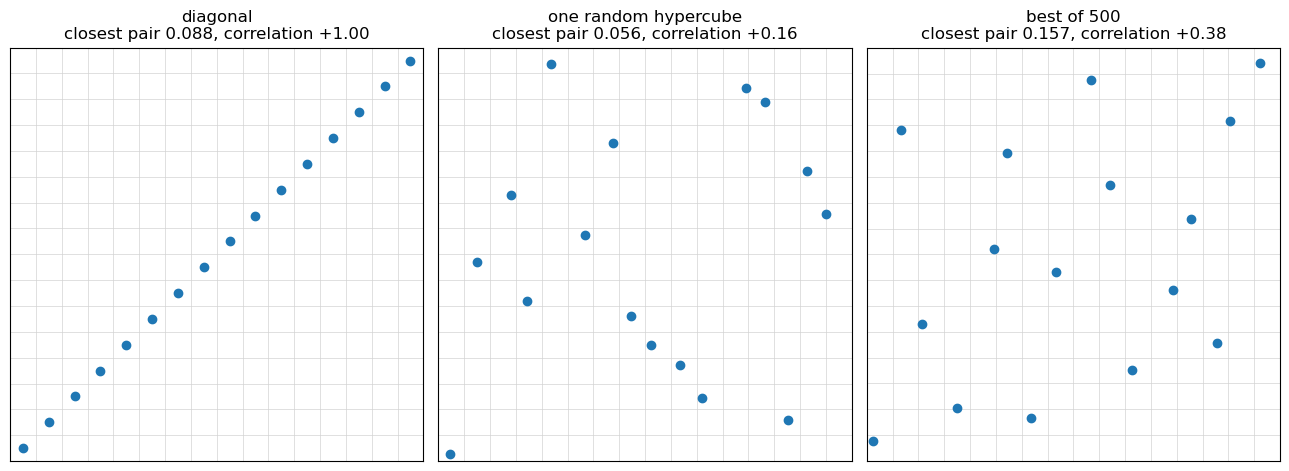

Figure: three 16-run Latin hypercubes on the same grid. Left, the diagonal: points in a line from corner to corner, closest pair 0.088, correlation +1.00, two corners of the square empty. Middle, one random hypercube, closest pair 0.056, correlation +0.16. Right, the best of 500 random ones, closest pair 0.157, correlation +0.38.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
panels = (("diagonal", diag, d_diag, r_diag), ("one random hypercube", P, d_random, r_random),
          (f"best of {TRIES}", best, best_d, r_best))
for ax, (name, Q, closest, corr) in zip(axes, panels):
    for k in range(N + 1):                 # the bin edges
        ax.axhline(k / N, color="lightgray", lw=0.5)
        ax.axvline(k / N, color="lightgray", lw=0.5)
    ax.plot(Q[:, 0], Q[:, 1], "o", color="tab:blue", ms=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{name}\nclosest pair {closest:.3f}, correlation {corr:+.2f}")
plt.tight_layout()
plt.show()
print(f"Figure: three {N}-run Latin hypercubes on the same grid. Left, the diagonal: points in a line "
      f"from corner to corner, closest pair {d_diag:.3f}, correlation {r_diag:+.2f}, two corners of the square "
      f"empty. Middle, one random hypercube, closest pair {d_random:.3f}, correlation {r_random:+.2f}. Right, "
      f"the best of {TRIES} random ones, closest pair {best_d:.3f}, correlation {r_best:+.2f}.")

By the closest pair alone, the diagonal beats the random hypercube. Is it the better design? What
does the closest pair miss that the correlation catches, and which of the two numbers matters more
if the next step is fitting a regression?

---

## Three dimensions: the number of runs does not grow

Here is the question this notebook exists for. A three-level factorial in three factors is a
$3 \times 3 \times 3$ grid, 27 runs. A three-run Latin hypercube in three factors cuts each axis into
3 bins, so its grid also has 27 cells. How many runs does it have?

Predict before you run it. Then check: one run per bin, on every axis. This time each run sits at
the middle of its cell (a **centered** hypercube), which makes the picture easier to read.

In [8]:
N3 = 3
rng3 = np.random.default_rng(SEED)

# A 3-run hypercube in 3 factors, centered: each run at the middle of its cell
P3 = np.empty((N3, 3))
for j in range(3):
    P3[:, j] = (rng3.permutation(N3) + 0.5) / N3

# The 3-level factorial: every cell of the same 3 x 3 x 3 grid
grid3 = np.array(list(itertools.product((np.arange(N3) + 0.5) / N3, repeat=3)))
print("Latin hypercube runs:", len(P3), "   cells in its grid:", N3 ** 3,
      "   3-level factorial:", len(grid3), "runs")
print("bin of each factor, one row per run:")
print(np.floor(P3 * N3).astype(int))

Latin hypercube runs: 3    cells in its grid: 27    3-level factorial: 27 runs
bin of each factor, one row per run:
[[1 0 0]
 [0 1 1]
 [2 2 2]]


### The picture

Left, the factorial. Right, the hypercube, with each run's **shadow** on the three back walls of the
cube. The grid lines on each wall are the bin edges. Each wall is a two-factor view of the design.

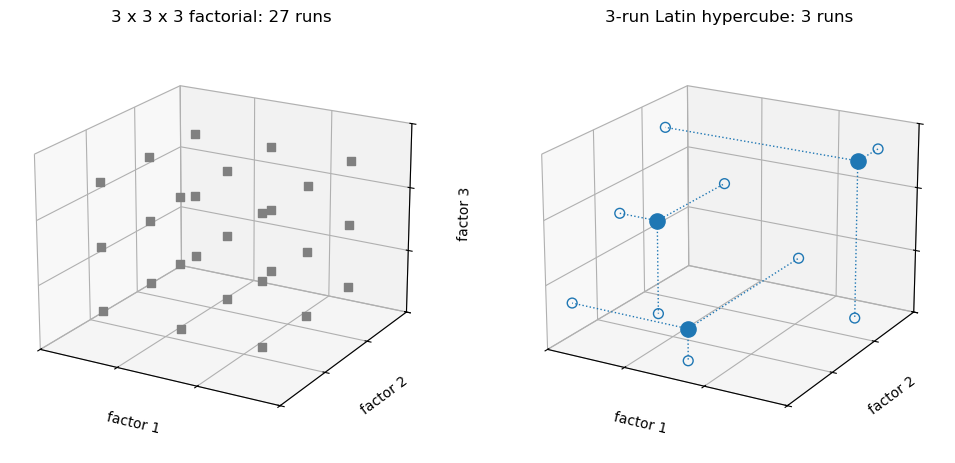

Figure: two cubes divided into a 3 by 3 by 3 grid. Left, 27 gray squares, one in every cell. Right, 3 blue points joined by dotted lines to their shadows (open circles) on the floor and two back walls; on each wall the 3 shadows fall in different rows and different columns of the 3 by 3 grid.


In [9]:
fig = plt.figure(figsize=(12, 5.5))
axF = fig.add_subplot(1, 2, 1, projection="3d")
axL = fig.add_subplot(1, 2, 2, projection="3d")
axF.scatter(*grid3.T, s=40, color="gray", marker="s", depthshade=False)
axF.set_title(f"3 x 3 x 3 factorial: {len(grid3)} runs")
axL.scatter(*P3.T, s=120, color="tab:blue", depthshade=False)
for p in P3:
    # Its shadow on each back wall: the same point with one coordinate pushed to that wall
    for wall, at in ((0, 0.0), (1, 1.0), (2, 0.0)):
        shadow = p.copy()
        shadow[wall] = at
        axL.scatter(*shadow, s=50, facecolors="none", edgecolors="tab:blue", depthshade=False)
        axL.plot(*zip(p, shadow), color="tab:blue", ls=":", lw=1)
axL.set_title(f"3-run Latin hypercube: {len(P3)} runs")

ticks = np.arange(N3 + 1) / N3              # the bin edges, as grid lines on every wall
for ax in (axF, axL):
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_zticks(ticks)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)
    ax.set_xlabel("factor 1")
    ax.set_ylabel("factor 2")
    ax.set_zlabel("factor 3")
    ax.view_init(elev=20, azim=-60)
plt.show()
print(f"Figure: two cubes divided into a 3 by 3 by 3 grid. Left, {len(grid3)} gray squares, one in every "
      f"cell. Right, {len(P3)} blue points joined by dotted lines to their shadows (open circles) on the "
      f"floor and two back walls; on each wall the {len(P3)} shadows fall in different rows and different "
      f"columns of the 3 by 3 grid.")

### Every face is a two-dimensional hypercube

Three runs make a thin example, so take eight runs in three dimensions and look at the design
face-on from each pair of axes. Each view is a two-factor design, and the rule says each must have one
run in every row and every column.

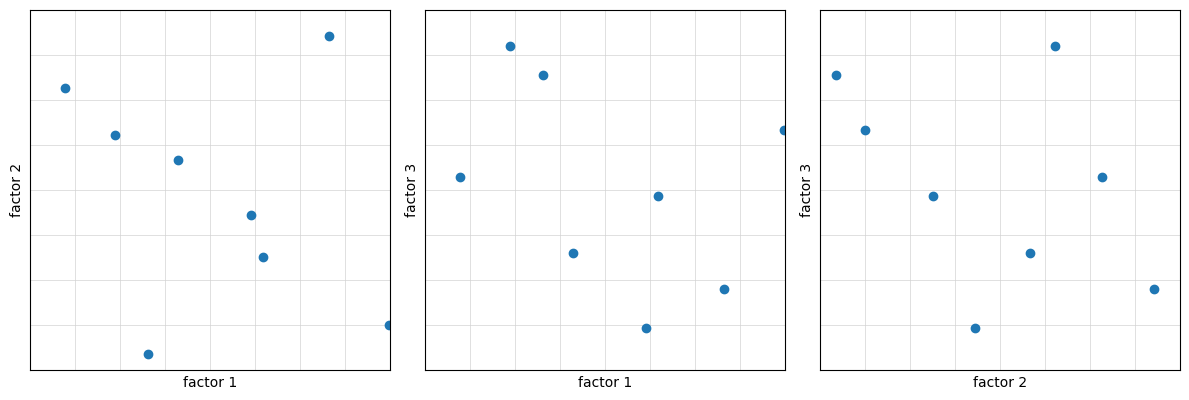

Figure: the 8-run hypercube in three dimensions seen face-on from each of its three pairs of axes. On 3 of the 3 faces every row and every column of the 8 by 8 grid holds exactly one point.


In [10]:
N8 = 8
rng8 = np.random.default_rng(SEED)
P8 = np.empty((N8, 3))                       # 8 runs, 3 factors
for j in range(3):
    P8[:, j] = (rng8.permutation(N8) + rng8.random(N8)) / N8

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
full_faces = 0                               # faces where every row and column holds exactly one run
for ax, (a, b) in zip(axes, ((0, 1), (0, 2), (1, 2))):      # each pair of factors
    for k in range(N8 + 1):
        ax.axhline(k / N8, color="lightgray", lw=0.5)
        ax.axvline(k / N8, color="lightgray", lw=0.5)
    ax.plot(P8[:, a], P8[:, b], "o", color="tab:blue")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f"factor {a + 1}")
    ax.set_ylabel(f"factor {b + 1}")
    every_column = len(set(np.floor(P8[:, a] * N8))) == N8
    every_row = len(set(np.floor(P8[:, b] * N8))) == N8
    full_faces += every_column and every_row
plt.tight_layout()
plt.show()
print(f"Figure: the {N8}-run hypercube in three dimensions seen face-on from each of its three pairs of "
      f"axes. On {full_faces} of the 3 faces every row and every column of the {N8} by {N8} grid holds "
      f"exactly one point.")

## How the run counts grow

A factorial's size is fixed by its levels and factors, $L^k$. A Latin hypercube's size is whatever
you choose; a common rule of thumb for computer experiments is ten runs per input (Loeppky, Sacks
and Welch, 2009).

In [11]:
print(f"{'factors':>8} {'2-level factorial':>18} {'3-level factorial':>18} {'hypercube, 10 per factor':>26}")
for k in range(2, 11):
    print(f"{k:8d} {2 ** k:18,d} {3 ** k:18,d} {10 * k:26d}")

 factors  2-level factorial  3-level factorial   hypercube, 10 per factor
       2                  4                  9                         20
       3                  8                 27                         30
       4                 16                 81                         40
       5                 32                243                         50
       6                 64                729                         60
       7                128              2,187                         70
       8                256              6,561                         80
       9                512             19,683                         90
      10              1,024             59,049                        100


## What the spreading buys: estimating an average

The simplest job a design can do is estimate the average of a function over the region. Take
$f(x) = \sum_j \sin(\pi x_j)$ in three dimensions. Each term averages $2/\pi$ over $[0, 1]$, so
the true mean is $3 \times 2/\pi$ exactly.

Estimate it a thousand times from 16 plain random points, and a thousand times from a 16-run Latin
hypercube. Both are unbiased. Predict which estimates will scatter less, and by roughly how much.

In [12]:
STUDY_SEED, REPS, D3 = 11, 1000, 3
print("study seed:", STUDY_SEED, f"   {REPS} repetitions of {N} runs in {D3} dimensions")
true_mean = D3 * 2 / np.pi
rng_s = np.random.default_rng(STUDY_SEED)
est_random, est_lhs = np.empty(REPS), np.empty(REPS)
for r in range(REPS):
    # Estimate 1: the average of f over 16 plain random points
    R = rng_s.random((N, D3))
    est_random[r] = np.sin(np.pi * R).sum(axis=1).mean()
    # Estimate 2: the average of f over a 16-run Latin hypercube
    L = np.empty((N, D3))
    for j in range(D3):
        L[:, j] = (rng_s.permutation(N) + rng_s.random(N)) / N
    est_lhs[r] = np.sin(np.pi * L).sum(axis=1).mean()
print(f"true mean {true_mean:.4f}")
print(f"random points:   mean of estimates {est_random.mean():.4f}   spread (sd) {est_random.std():.4f}")
print(f"Latin hypercube: mean of estimates {est_lhs.mean():.4f}   spread (sd) {est_lhs.std():.4f}")
print(f"ratio of spreads: {est_random.std() / est_lhs.std():.1f}")

study seed: 11    1000 repetitions of 16 runs in 3 dimensions
true mean 1.9099
random points:   mean of estimates 1.9067   spread (sd) 0.1315
Latin hypercube: mean of estimates 1.9098   spread (sd) 0.0176
ratio of spreads: 7.5


The two sets of estimates:

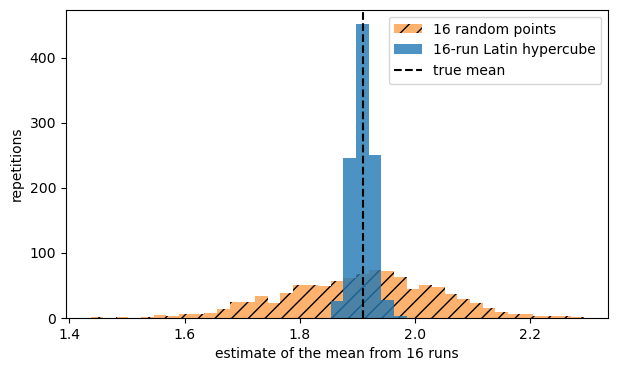

Figure: histograms of 1000 estimates each, centered on the true mean 1.9099 (dashed). The random-point estimates (hatched) spread from 1.44 to 2.29; the hypercube estimates (solid) form a much narrower spike, from 1.86 to 1.97.


In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
edges = np.linspace(min(est_random.min(), est_lhs.min()), max(est_random.max(), est_lhs.max()), 40)
ax.hist(est_random, bins=edges, color="tab:orange", alpha=0.6, hatch="//", label="16 random points")
ax.hist(est_lhs, bins=edges, color="tab:blue", alpha=0.8, label="16-run Latin hypercube")
ax.axvline(true_mean, color="black", ls="--", label="true mean")
ax.set_xlabel(f"estimate of the mean from {N} runs")
ax.set_ylabel("repetitions")
ax.legend()
plt.show()
print(f"Figure: histograms of {REPS} estimates each, centered on the true mean {true_mean:.4f} (dashed). The "
      f"random-point estimates (hatched) spread from {est_random.min():.2f} to {est_random.max():.2f}; the "
      f"hypercube estimates (solid) form a much narrower spike, from {est_lhs.min():.2f} to {est_lhs.max():.2f}.")

This function is a sum of one-factor pieces, and a Latin hypercube samples every one-factor slice
evenly. What do you expect to happen to the advantage when the factors interact? The first exercise
below tests it.

---

# Now the streamlined version

Each design above was built by hand, and a real study builds them again at a different size each
time. `orteach.doe` holds each step once: `lhs`, `maximin_lhs`, `min_distance`, `is_latin` and
`sampling_study`. In production, `scipy.stats.qmc.LatinHypercube` does the same job with better
optimizers; the last line checks that its designs pass the same test.

In [14]:
pkg_P = doe.lhs(N, D, np.random.default_rng(SEED))
pkg_best, pkg_best_d = doe.maximin_lhs(N, D, TRIES, MM_SEED)
pkg_P3 = doe.lhs(N3, 3, np.random.default_rng(SEED), centered=True)
pkg_P8 = doe.lhs(N8, 3, np.random.default_rng(SEED))
pkg_random, pkg_lhs = doe.sampling_study(N, D3, REPS, STUDY_SEED)
package_designs = (("16 runs, 2 factors", pkg_P), ("maximin", pkg_best),
                   ("3 runs, 3 factors", pkg_P3), ("8 runs, 3 factors", pkg_P8))
for name, Q in package_designs:
    print(f"{name:20} Latin: {doe.is_latin(Q)}   closest pair {doe.min_distance(Q):.3f}")
print(f"{'diagonal':20} Latin: {doe.is_latin(diag)}   closest pair {doe.min_distance(diag):.3f}")

from scipy.stats import qmc
S = qmc.LatinHypercube(d=2, seed=SEED).random(N)
print(f"scipy qmc.LatinHypercube, {N} runs: Latin {doe.is_latin(S)}")

16 runs, 2 factors   Latin: True   closest pair 0.056
maximin              Latin: True   closest pair 0.157
3 runs, 3 factors    Latin: True   closest pair 0.577
8 runs, 3 factors    Latin: True   closest pair 0.327
diagonal             Latin: True   closest pair 0.088
scipy qmc.LatinHypercube, 16 runs: Latin True


## The agreement assertion

The package must draw the same designs from the same seeds, find the same maximin winner and its
distance, and produce the same thousand estimates of each kind. Same arithmetic in the same order,
so agreement to `AGREEMENT_RTOL` is what must hold.

In [15]:
pairs = (("16 x 2", P, pkg_P), ("maximin", best, pkg_best), ("3 x 3", P3, pkg_P3), ("8 x 3", P8, pkg_P8),
         ("random estimates", est_random, pkg_random), ("hypercube estimates", est_lhs, pkg_lhs))
checks = [("maximin closest pair", best_d, pkg_best_d), ("diagonal closest pair", d_diag, doe.min_distance(diag)),
          ("random closest pair", d_random, doe.min_distance(P))]
for name, hand, packaged in pairs:
    assert hand.shape == packaged.shape, f"{name}: shapes differ"
    checks += [(f"{name} [{i}]", h, k) for i, (h, k) in enumerate(zip(hand.ravel(), packaged.ravel()))]
worst = max(rel_diff(h, k) for _, h, k in checks)
print(f"{len(checks)} numbers compared")
assert worst < AGREEMENT_RTOL, f"notebook and package disagree by {worst:.2e}"
print(f"notebook and package agree to {worst:.1e}")

2100 numbers compared
notebook and package agree to 0.0e+00


---

## Where to take this next

- Replace the sum with a product, $f(x) = \prod_j \sin(\pi x_j)$, whose mean is $(2/\pi)^3$. Run the
  sampling study again. Does the hypercube still win, and by as much?
- The maximin winner above is more correlated than the random hypercube it beat. Change the search so
  it skips any candidate whose factor correlation is above 0.1 in size. How much closest-pair distance
  does that cost?
- Run the maximin search with 50 tries, then 5000. How much does the closest pair improve each time
  you multiply the effort by ten?
- Fit a surrogate. Evaluate a test function of your choice at the 16 factorial points and at the 16
  maximin points, fit the same quadratic regression to each, and compare their prediction errors on
  a fine grid. Where does each design's surrogate do worst?
- `qmc.LatinHypercube(d=2, optimization="random-cd")` and `qmc.Sobol` are two more ways to fill
  space. Plot sixteen runs of each beside the maximin design.